In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore')

In [62]:
df = pd.read_csv(
    "../outputs/cleaned_manufacturing_data.csv"
)

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (4860, 21)


,record_id,production_date,production_line,machine_id,shift,product_id,batch_id,production_start_time,production_end_time,planned_production_time_minutes,...,downtime_type,downtime_reason,minor_stop_minutes,total_count,reject_count,good_count,ideal_cycle_time_seconds,defect_reason,operator_id,production_duration_minutes
0,REC-000001,2026-07-01,Line-A,M-01,A,P-100,B-260701-M-01-A-1,2026-07-01 06:00:00,2026-07-01 08:18:00,138,...,Unplanned,Material shortage,2,306,2,304,17.64,Surface defect,OP-028,138.0
1,REC-000002,2026-07-01,Line-A,M-01,A,P-400,B-260701-M-01-A-2,2026-07-01 08:30:00,2026-07-01 10:52:00,142,...,Unplanned,Utilities,8,255,11,244,21.56,Surface defect,OP-003,142.0
2,REC-000003,2026-07-01,Line-A,M-01,A,P-400,B-260701-M-01-A-3,2026-07-01 11:00:00,2026-07-01 13:25:00,145,...,Unplanned,Utilities,6,325,15,310,21.56,Process variation,OP-010,145.0
3,REC-000004,2026-07-01,Line-A,M-01,B,P-500,B-260701-M-01-B-1,2026-07-01 14:00:00,2026-07-01 16:18:00,138,...,Unplanned,Quality / process,9,198,2,196,26.46,Surface defect,OP-025,138.0
4,REC-000005,2026-07-01,Line-A,M-01,B,P-200,B-260701-M-01-B-2,2026-07-01 16:30:00,2026-07-01 18:48:00,138,...,Unplanned,Quality / process,11,286,8,278,23.52,Assembly defect,OP-009,138.0


In [63]:
#Calculate machine operating time
df['run_time_minutes']=(
    df['planned_production_time_minutes']-df['downtime_minutes']
)

df['run_time_seconds']=(
    df['run_time_minutes']*60
)

df[['planned_production_time_minutes','downtime_minutes','run_time_minutes']].head()

,planned_production_time_minutes,downtime_minutes,run_time_minutes
0,138,30,108
1,142,38,104
2,145,16,129
3,138,38,100
4,138,20,118


In [64]:
# Calculate Availability

df['Availability'] = np.where(
    df['planned_production_time_minutes'] > 0,
    (df['run_time_minutes'] / df['planned_production_time_minutes']) * 100,
    np.nan
)

df[['machine_id', 'Availability']].head()

,machine_id,Availability
0,M-01,78.260870
1,M-01,73.239437
2,M-01,88.965517
3,M-01,72.463768
4,M-01,85.507246


In [65]:
df['performance'] = np.where(
    df['run_time_seconds'] > 0,
    (
        df['ideal_cycle_time_seconds'] *
        df['total_count'] /
        df['run_time_seconds']
    ) * 100,
    np.nan
)

df[['machine_id', 'performance']].head()

,machine_id,performance
0,M-01,83.300000
1,M-01,88.105769
2,M-01,90.529716
3,M-01,87.318000
4,M-01,95.010169


In [66]:
#Calculate Quality
df['quality'] = np.where(
    df['total_count'] > 0,
    (df['good_count'] / df['total_count']) * 100,
    np.nan
)
df[['total_count', 'good_count',
    'reject_count', 'quality']].head()

,total_count,good_count,reject_count,quality
0,306,304,2,99.346405
1,255,244,11,95.686275
2,325,310,15,95.384615
3,198,196,2,98.989899
4,286,278,8,97.202797


In [67]:
#Calculate Overall Equipment Effectiveness (OEE)
# Calculate Overall Equipment Effectiveness (OEE)

df['oee_percentage'] = (
    df['Availability'] *
    df['performance'] *
    df['quality']
) / 10000

df[['machine_id', 'Availability',
    'performance', 'quality',
    'oee_percentage']].head()

,machine_id,Availability,performance,quality,oee_percentage
0,M-01,78.260870,83.300000,99.346405,64.765217
1,M-01,73.239437,88.105769,95.686275,61.744601
2,M-01,88.965517,90.529716,95.384615,76.822989
3,M-01,72.463768,87.318000,98.989899,62.634783
4,M-01,85.507246,95.010169,97.202797,78.968116


In [68]:
kpi_columns = [
    'Availability',
    'performance',
    'quality',
    'oee_percentage'
]

df[kpi_columns].describe()

,Availability,performance,quality,oee_percentage
count,4860.000000,4860.000000,4860.000000,4860.000000
mean,84.320763,90.265472,96.770713,73.648353
std,10.403532,4.460420,2.055234,9.886089
min,48.484848,75.868571,90.243902,39.243210
25%,78.676471,87.268106,95.622281,68.110126
50%,86.666667,90.312495,97.183099,74.841069
75%,92.142857,93.242296,98.319328,80.796963
max,98.620690,99.772500,100.000000,96.433103


In [69]:
# print("Performance above 100%:",
#       (df['performance'] > 100).sum())

# print("OEE above 100%:",
#       (df['oee_percentage'] > 100).sum())

# print("Missing OEE values:",
#       df['oee_percentage'].isnull().sum())

# Check Performance above 100%
print("Performance above 100%:",
      (df['performance'] > 100).sum())

# Check OEE above 100%
print("OEE above 100%:",
      (df['oee_percentage'] > 100).sum())

# Check missing OEE values
print("Missing OEE values:",
      df['oee_percentage'].isnull().sum())

# Check negative OEE values
print("Negative OEE values:",
      (df['oee_percentage'] < 0).sum())

# Check missing Performance values
print("Missing Performance values:",
      df['performance'].isnull().sum())

# Check negative Performance values
print("Negative Performance values:",
      (df['performance'] < 0).sum())

Performance above 100%: 0
OEE above 100%: 0
Missing OEE values: 0
Negative OEE values: 0
Missing Performance values: 0
Negative Performance values: 0


In [70]:
def calculate_kpis(data):

    planned = data['planned_production_time_minutes'].sum()
    downtime = data['downtime_minutes'].sum()
    runtime = planned - downtime

    total = data['total_count'].sum()
    good = data['good_count'].sum()

    ideal_time = (
        data['ideal_cycle_time_seconds'] *
        data['total_count']
    ).sum()

    availability = (runtime / planned) * 100 if planned else np.nan

    performance = (
        ideal_time / (runtime * 60)
    ) * 100 if runtime > 0 else np.nan

    quality = (good / total) * 100 if total else np.nan

    oee = (
        availability * performance * quality
    ) / 10000

    return pd.Series({
        'Availability (%)': availability,
        'Performance (%)': performance,
        'Quality (%)': quality,
        'OEE (%)': oee,
        'Total Production': total,
        'Good Production': good,
        'Rejected Production': total - good,
        'Downtime (Minutes)': downtime
    })


overall_kpis = calculate_kpis(df)

display(overall_kpis)

Availability (%)       8.433379e+01
Performance (%)        9.026412e+01
Quality (%)            9.675160e+01
OEE (%)                7.365036e+01
Total Production       1.311416e+06
Good Production        1.268816e+06
Rejected Production    4.260000e+04
Downtime (Minutes)     1.055060e+05
dtype: float64

In [71]:
#Machine-wise OEE analysis
machine_analysis=df.groupby(
    'machine_id'
).apply(
    calculate_kpis,
    include_groups=False
).reset_index()

machine_analysis

,machine_id,Availability (%),Performance (%),Quality (%),OEE (%),Total Production,Good Production,Rejected Production,Downtime (Minutes)
0,M-01,84.601954,91.144626,96.755593,74.608369,225804.0,218478.0,7326.0,17286.0
1,M-02,84.212399,90.732536,96.686815,73.876505,220694.0,213382.0,7312.0,17753.0
2,M-03,84.236809,90.462471,96.714737,73.699240,220165.0,212932.0,7233.0,17677.0
3,M-04,84.327353,90.507763,96.824030,73.898811,217099.0,210204.0,6895.0,17567.0
4,M-05,84.814534,89.556277,96.899081,73.601383,216323.0,209615.0,6708.0,17051.0
5,M-06,83.809549,89.176166,96.628038,72.218001,211331.0,204205.0,7126.0,18172.0


In [72]:
#Sort machines by OEE
machine_analysis = machine_analysis.sort_values(
    by='OEE (%)',
    ascending=False
)

machine_analysis

,machine_id,Availability (%),Performance (%),Quality (%),OEE (%),Total Production,Good Production,Rejected Production,Downtime (Minutes)
0,M-01,84.601954,91.144626,96.755593,74.608369,225804.0,218478.0,7326.0,17286.0
3,M-04,84.327353,90.507763,96.824030,73.898811,217099.0,210204.0,6895.0,17567.0
1,M-02,84.212399,90.732536,96.686815,73.876505,220694.0,213382.0,7312.0,17753.0
2,M-03,84.236809,90.462471,96.714737,73.699240,220165.0,212932.0,7233.0,17677.0
4,M-05,84.814534,89.556277,96.899081,73.601383,216323.0,209615.0,6708.0,17051.0
5,M-06,83.809549,89.176166,96.628038,72.218001,211331.0,204205.0,7126.0,18172.0


In [73]:
#Shift-wise OEE analysis
shift_analysis = df.groupby(
    'shift'
).apply(
    calculate_kpis,
    include_groups=False
).reset_index()

shift_analysis

,shift,Availability (%),Performance (%),Quality (%),OEE (%),Total Production,Good Production,Rejected Production,Downtime (Minutes)
0,A,84.079110,91.022130,96.730343,74.028309,440352.0,425954.0,14398.0,35758.0
1,B,84.735873,89.909251,96.727245,73.692028,435138.0,420897.0,14241.0,34244.0
2,C,84.186780,89.863710,96.797392,73.230483,435926.0,421965.0,13961.0,35504.0


In [74]:
#Product-wise OEE analysis
product_analysis = df.groupby(
    'product_id'
).apply(
    calculate_kpis,
    include_groups=False
).reset_index()

product_analysis

,product_id,Availability (%),Performance (%),Quality (%),OEE (%),Total Production,Good Production,Rejected Production,Downtime (Minutes)
0,P-100,83.792477,90.285851,97.032044,73.407411,338718.0,328665.0,10053.0,21768.0
1,P-200,84.678891,90.177155,96.977869,74.053285,252140.0,244520.0,7620.0,20228.0
2,P-300,84.152447,90.439275,97.002542,73.825591,201037.0,195011.0,6026.0,20924.0
3,P-400,84.730139,90.237309,95.794651,73.242864,287491.0,275401.0,12090.0,21055.0
4,P-500,84.307766,90.185852,97.064604,73.801788,232030.0,225219.0,6811.0,21531.0


In [75]:
#Downtime analysis
downtime_analysis = df.groupby(
    'downtime_reason'
).agg(
    Total_Downtime=('downtime_minutes', 'sum'),
    Number_of_Records=('record_id', 'count')
).reset_index()

downtime_analysis = downtime_analysis.sort_values(
    by='Total_Downtime',
    ascending=False
)

downtime_analysis

,downtime_reason,Total_Downtime,Number_of_Records
0,Equipment failure,20915,942
6,Setup / changeover,19285,884
1,Material shortage,15728,720
2,Minor stops,12686,582
5,Quality / process,12180,548
3,Operator-related,10788,495
7,Utilities,7923,389
4,Other / unclassified,6001,300


In [76]:
#Downtime contribution percentage
total_downtime = downtime_analysis[
    'Total_Downtime'
].sum()

downtime_analysis['Contribution (%)'] = (
    downtime_analysis['Total_Downtime'] /
    total_downtime
) * 100

downtime_analysis

,downtime_reason,Total_Downtime,Number_of_Records,Contribution (%)
0,Equipment failure,20915,942,19.823517
6,Setup / changeover,19285,884,18.278581
1,Material shortage,15728,720,14.907209
2,Minor stops,12686,582,12.023961
5,Quality / process,12180,548,11.544367
3,Operator-related,10788,495,10.225011
7,Utilities,7923,389,7.509526
4,Other / unclassified,6001,300,5.687828


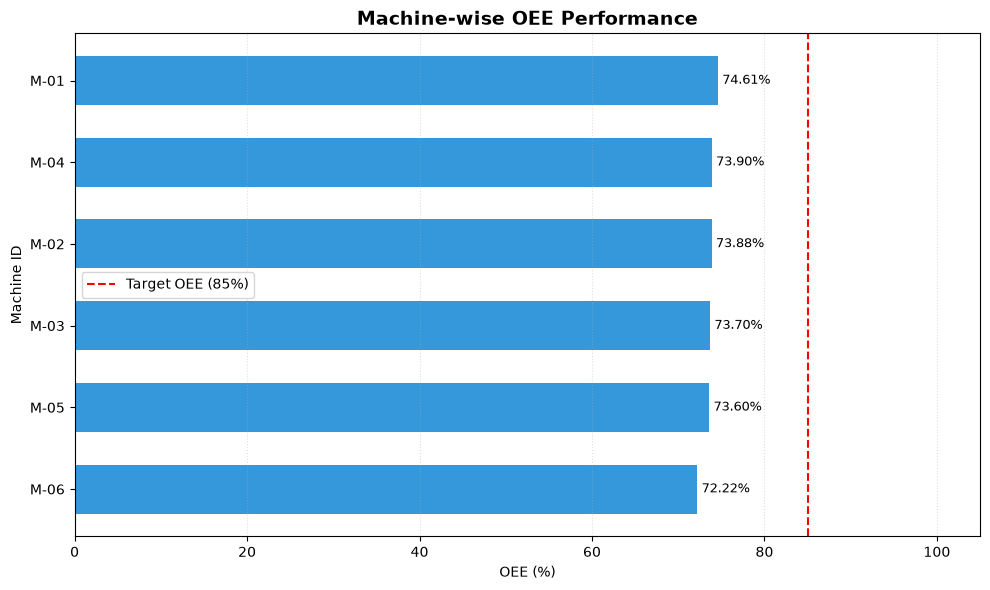

In [77]:
# #Visualise the results *
# plt.figure(figsize=(10, 5))

# plt.bar(
#     machine_analysis['machine_id'],
#     machine_analysis['OEE (%)']
# )

# plt.title('Machine-wise OEE Comparison')
# plt.xlabel('Machine')
# plt.ylabel('OEE (%)')
# plt.grid(axis='y', alpha=0.3)

# plt.show()
plt.figure(figsize=(10, 6))

machine_sorted = machine_analysis.sort_values(
    by='OEE (%)',
    ascending=True
)

bars = plt.barh(
    machine_sorted['machine_id'],
    machine_sorted['OEE (%)'],
    color='#3498DB',
    height=0.6
)

# Add OEE percentage labels
for bar in bars:
    width = bar.get_width()

    plt.text(
        width + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f'{width:.2f}%',
        va='center',
        fontsize=9
    )

# Target OEE
plt.axvline(
    x=85,
    color='red',
    linestyle='--',
    label='Target OEE (85%)'
)

plt.title('Machine-wise OEE Performance', fontsize=14, fontweight='bold')
plt.xlabel('OEE (%)')
plt.ylabel('Machine ID')

plt.xlim(0, 105)
plt.legend()
plt.grid(axis='x', linestyle=':', alpha=0.4)

plt.tight_layout()
plt.show()

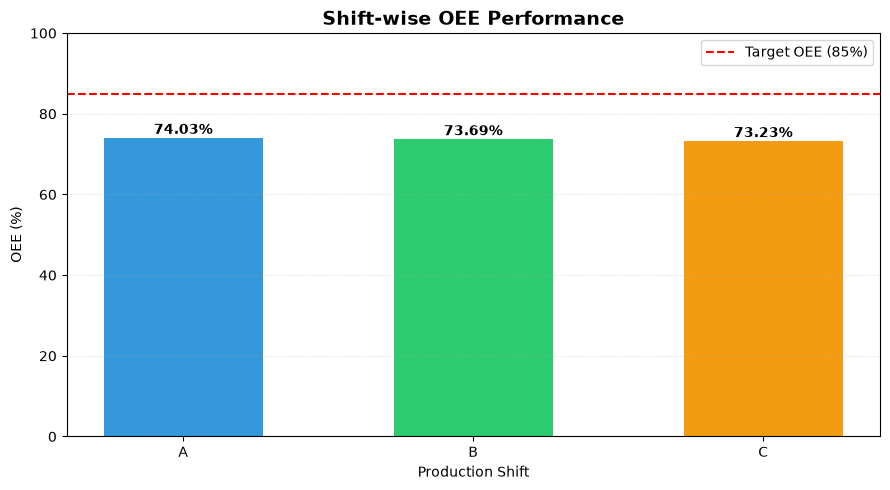

In [78]:
# #Shift-wise OEE chart *
# plt.figure(figsize=(8, 5))

# plt.bar(
#     shift_analysis['shift'],
#     shift_analysis['OEE (%)']
# )

# plt.title('Shift-wise OEE Comparison')
# plt.xlabel('Shift')
# plt.ylabel('OEE (%)')

# plt.show()
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

bars = plt.bar(
    shift_analysis['shift'],
    shift_analysis['OEE (%)'],
    color=['#3498DB', '#2ECC71', '#F39C12'],
    width=0.55
)

# Add OEE value labels
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        f'{height:.2f}%',
        ha='center',
        fontsize=10,
        fontweight='bold'
    )

# Target OEE line
plt.axhline(
    y=85,
    color='red',
    linestyle='--',
    label='Target OEE (85%)'
)

plt.title('Shift-wise OEE Performance', fontsize=14, fontweight='bold')
plt.xlabel('Production Shift')
plt.ylabel('OEE (%)')

plt.ylim(0, 100)
plt.legend()
plt.grid(axis='y', linestyle=':', alpha=0.4)

plt.tight_layout()
plt.show()

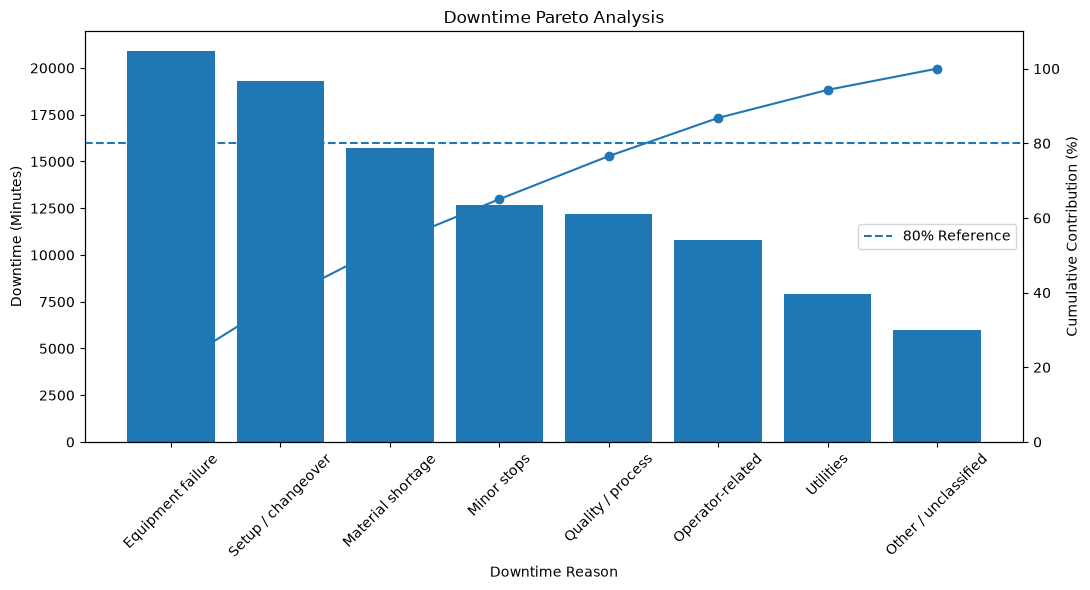

In [79]:
#Downtime Pareto-style chart
pareto = downtime_analysis.copy()

pareto['Cumulative (%)'] = (
    pareto['Contribution (%)'].cumsum()
)

fig, ax1 = plt.subplots(figsize=(11, 6))

ax1.bar(
    pareto['downtime_reason'],
    pareto['Total_Downtime']
)

ax1.set_xlabel('Downtime Reason')
ax1.set_ylabel('Downtime (Minutes)')
ax1.tick_params(axis='x', rotation=45)

ax2 = ax1.twinx()

ax2.plot(
    pareto['downtime_reason'],
    pareto['Cumulative (%)'],
    marker='o',
    linestyle='-'
)

ax2.axhline(
    80,
    linestyle='--',
    label='80% Reference'
)

ax2.set_ylabel('Cumulative Contribution (%)')
ax2.set_ylim(0, 110)
ax2.legend(loc='center right')

plt.title('Downtime Pareto Analysis')
plt.tight_layout()
plt.show()

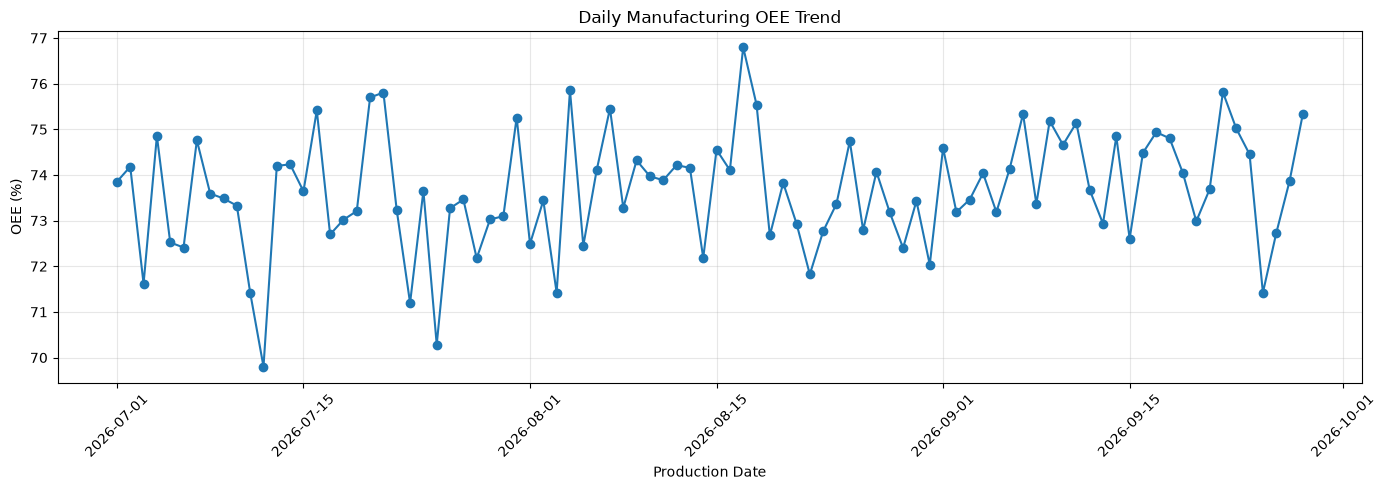

In [80]:
#Production trend analysis
#Daily OEE trend
df['production_date'] = pd.to_datetime(
    df['production_date']
)

daily_analysis = df.groupby(
    'production_date'
).apply(
    calculate_kpis,
    include_groups=False
).reset_index()

plt.figure(figsize=(14, 5))

plt.plot(
    daily_analysis['production_date'],
    daily_analysis['OEE (%)'],
    marker='o'
)

plt.title('Daily Manufacturing OEE Trend')
plt.xlabel('Production Date')
plt.ylabel('OEE (%)')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

In [81]:
#Production loss analysis
df['availability_loss_minutes'] = (
    df['downtime_minutes']
)

df['performance_loss_minutes'] = (
    df['run_time_minutes'] -
    (
        df['ideal_cycle_time_seconds'] *
        df['total_count'] / 60
    )
)

df['quality_loss_minutes'] = (
    df['ideal_cycle_time_seconds'] *
    df['reject_count'] / 60
)

df['fully_productive_time_minutes'] = (
    df['ideal_cycle_time_seconds'] *
    df['good_count'] / 60
)

In [82]:
#Loss summary
loss_summary = pd.Series({
    'Availability Loss': df['availability_loss_minutes'].sum(),
    'Performance Loss': df['performance_loss_minutes'].sum(),
    'Quality Loss': df['quality_loss_minutes'].sum(),
    'Fully Productive Time':
        df['fully_productive_time_minutes'].sum()
})

display(loss_summary)

Availability Loss        105506.000000
Performance Loss          55295.533833
Quality Loss              16569.493333
Fully Productive Time    496090.972833
dtype: float64

In [83]:
# Calculate production time losses

df['run_time_minutes'] = (
    df['planned_production_time_minutes']
    - df['downtime_minutes']
)

df['availability_loss'] = df['downtime_minutes']

df['performance_loss'] = (
    df['run_time_minutes']
    - (
        df['ideal_cycle_time_seconds']
        * df['total_count']
        / 60
    )
)

df['quality_loss'] = (
    df['ideal_cycle_time_seconds']
    * df['reject_count']
    / 60
)

df['fully_productive_time'] = (
    df['ideal_cycle_time_seconds']
    * df['good_count']
    / 60
)

In [84]:
# Total planned production time
planned_time = df['planned_production_time_minutes'].sum()

# Total losses
availability_loss = df['availability_loss'].sum()
performance_loss = df['performance_loss'].sum()
quality_loss = df['quality_loss'].sum()

# Remaining productive time
fully_productive_time = df['fully_productive_time'].sum()

# Reconciled time
reconciled_time = (
    availability_loss
    + performance_loss
    + quality_loss
    + fully_productive_time
)

print("Planned Production Time:", planned_time)
print("Total Reconciled Time:", reconciled_time)
print("Difference:", planned_time - reconciled_time)

Planned Production Time: 673462
Total Reconciled Time: 673462.0
Difference: 0.0


In [85]:
# Validate individual loss components

loss_columns = [
    'availability_loss',
    'performance_loss',
    'quality_loss',
    'fully_productive_time'
]

for col in loss_columns:
    print(
        col,
        "Negative records:",
        (df[col] < -0.01).sum()
    )

# Validate production counts
print(
    "Count mismatch:",
    (df['good_count'] + df['reject_count']
     != df['total_count']).sum()
)

# Validate runtime
print(
    "Runtime mismatch:",
    (
        df['run_time_minutes'] !=
        df['planned_production_time_minutes']
        - df['downtime_minutes']
    ).sum()
)

availability_loss Negative records: 0
performance_loss Negative records: 0
quality_loss Negative records: 0
fully_productive_time Negative records: 0
Count mismatch: 0
Runtime mismatch: 0


In [86]:
import os

os.makedirs('../outputs', exist_ok=True)

df.to_csv(
    '../outputs/oee_calculated_data.csv',
    index=False
)

machine_analysis.to_csv(
    '../outputs/machine_analysis.csv',
    index=False
)

shift_analysis.to_csv(
    '../outputs/shift_analysis.csv',
    index=False
)

product_analysis.to_csv(
    '../outputs/product_analysis.csv',
    index=False
)

downtime_analysis.to_csv(
    '../outputs/downtime_analysis.csv',
    index=False
)

# Export loss summary as a proper table
loss_waterfall_summary = loss_summary.rename_axis(
    'Loss Category'
).reset_index(name='Time (Minutes)')

loss_waterfall_summary.to_csv(
    '../outputs/loss_waterfall_summary.csv',
    index=False
)

daily_analysis.to_csv(
    '../outputs/daily_oee_analysis.csv',
    index=False
)

print("All analysis files exported successfully!")

All analysis files exported successfully!
